<a href="https://colab.research.google.com/github/sofiyapriz/GeometryLab7/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%9F%D1%80%D0%B8%D0%B7_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [ ]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)


TensorFlow: 2.21.0
Keras: 3.13.2


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [ ]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("x_train_full shape:", x_train_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
print("Кількість класів:", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train_full shape: (60000, 28, 28)
y_train_full shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

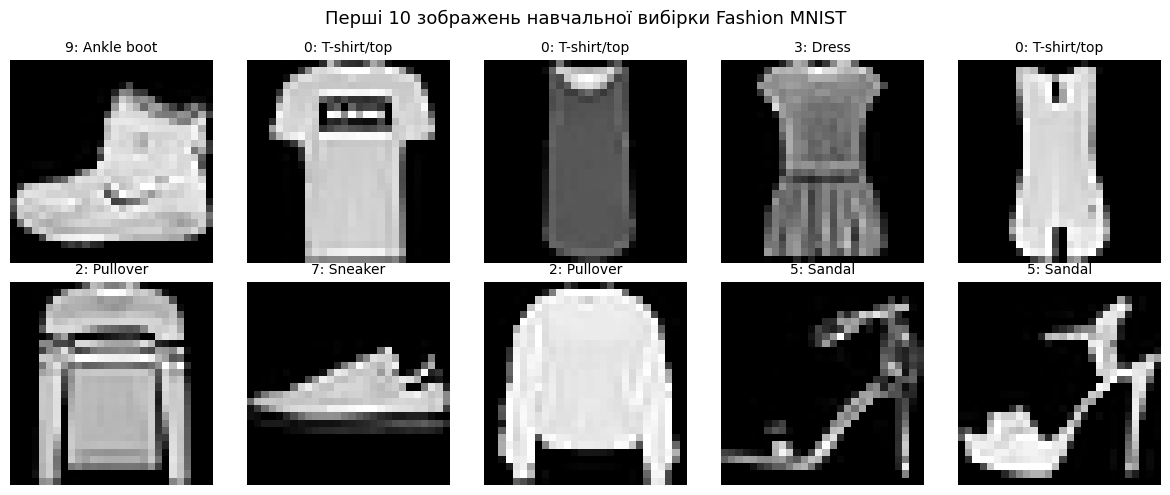

In [ ]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}", fontsize=10)
    ax.axis("off")

plt.suptitle("Перші 10 зображень навчальної вибірки Fashion MNIST", fontsize=13)
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [ ]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(f"Діапазон x_train_full: [{x_train_full.min()}, {x_train_full.max()}], dtype: {x_train_full.dtype}")
print(f"Діапазон x_test:       [{x_test.min()}, {x_test.max()}], dtype: {x_test.dtype}")

assert np.all((x_train_full >= 0.0) & (x_train_full <= 1.0))
assert np.all((x_test >= 0.0) & (x_test <= 1.0))


Діапазон x_train_full: [0.0, 1.0], dtype: float32
Діапазон x_test:       [0.0, 1.0], dtype: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

Обрано 256 і 128 нейронів, через те що зображення проходить через два етапи. На першому етапі модель помічає основні деталі одягу, а на другому етапі зменшує кількість нейронів удвічі, зберігаючи необхідну інформацію та узагальнюючи її.

Dropout під час навчання випадково вимикає частину нейронів. Це потрібно, щоб модель не зазубрила правильні відповіді на навчальних даних і краще працювала на нових. Для кожного шару задаємо своє значення Dropout: для першого шару 0.3, а для другого 0.2.

Швидкість навчання обрано 0.001, це стандарт при якому мережа навчається досить швидко, але водночас плавно, без різких стрибків помилки.

In [ ]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28), name="input_image"),
    layers.Flatten(name="flatten"),
    layers.Dense(256, activation="relu", name="dense_256"),
    layers.Dropout(0.3, name="dropout_1"),
    layers.Dense(128, activation="relu", name="dense_128"),
    layers.Dropout(0.2, name="dropout_2"),
    layers.Dense(10, activation="softmax", name="output")
], name="fashion_mnist_mlp")

learning_rate_1 = 0.001
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_1),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

epochs_task1 = len(history.history["loss"])
print(f"Фактична кількість епох навчання: {epochs_task1}")

Epoch 1/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.7860 - loss: 0.5966 - val_accuracy: 0.8484 - val_loss: 0.4101 - learning_rate: 0.0010
Epoch 2/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8425 - loss: 0.4331 - val_accuracy: 0.8723 - val_loss: 0.3498 - learning_rate: 0.0010
Epoch 3/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8545 - loss: 0.3947 - val_accuracy: 0.8764 - val_loss: 0.3381 - learning_rate: 0.0010
Epoch 4/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8628 - loss: 0.3712 - val_accuracy: 0.8844 - val_loss: 0.3206 - learning_rate: 0.0010
Epoch 5/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8694 - loss: 0.3572 - val_accuracy: 0.8813 - val_loss: 0.3169 - learning_rate: 0.0010
Epoch 6/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8734 - loss: 0.3431 - val_accuracy: 0.8831 - val_loss: 0.3087 - learning_rate: 0.0010
Epoch 7/30
797/797 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8780 - loss: 0.3314 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів у моделі:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())


Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів у моделі: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save("fashion_mnist_model.keras")
print("Модель успішно збережено у файл fashion_mnist_model.keras")

Модель успішно збережено у файл fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

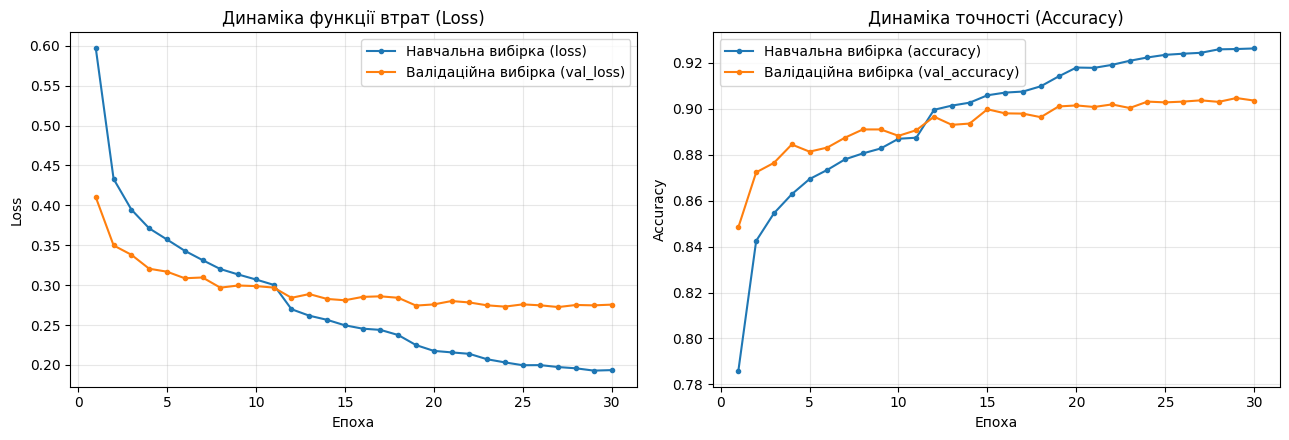

In [ ]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs_range = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Графік втрат (Loss)
axes[0].plot(epochs_range, history.history["loss"], label="Навчальна вибірка (loss)", marker="o", ms=3)
axes[0].plot(epochs_range, history.history["val_loss"], label="Валідаційна вибірка (val_loss)", marker="o", ms=3)
axes[0].set_title("Динаміка функції втрат (Loss)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Графік точності (Accuracy)
axes[1].plot(epochs_range, history.history["accuracy"], label="Навчальна вибірка (accuracy)", marker="o", ms=3)
axes[1].plot(epochs_range, history.history["val_accuracy"], label="Валідаційна вибірка (val_accuracy)", marker="o", ms=3)
axes[1].set_title("Динаміка точності (Accuracy)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss_1, test_acc_1 = model.evaluate(x_test, y_test, verbose=0)
y_pred_probs = model.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

print(f"Тестові втрати (Loss): {test_loss_1:.4f}")
print(f"Тестова точність (Accuracy): {test_acc_1:.4f} ({test_acc_1:.2%})")
print(f"Поріг 0.87 досягнуто: {'ТАК' if test_acc_1 >= 0.87 else 'НІ'}\n")

print("Класифікаційний звіт:")
print(classification_report(y_test, y_pred_classes, target_names=class_names, digits=3))


Тестові втрати (Loss): 0.3129
Тестова точність (Accuracy): 0.8935 (89.35%)
Поріг 0.87 досягнуто: ТАК

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top      0.842     0.847     0.844      1000
     Trouser      0.990     0.974     0.982      1000
    Pullover      0.796     0.841     0.818      1000
       Dress      0.880     0.906     0.893      1000
        Coat      0.806     0.815     0.811      1000
      Sandal      0.982     0.969     0.975      1000
       Shirt      0.748     0.677     0.711      1000
     Sneaker      0.945     0.967     0.956      1000
         Bag      0.977     0.982     0.980      1000
  Ankle boot      0.965     0.957     0.961      1000

    accuracy                          0.893     10000
   macro avg      0.893     0.894     0.893     10000
weighted avg      0.893     0.893     0.893     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

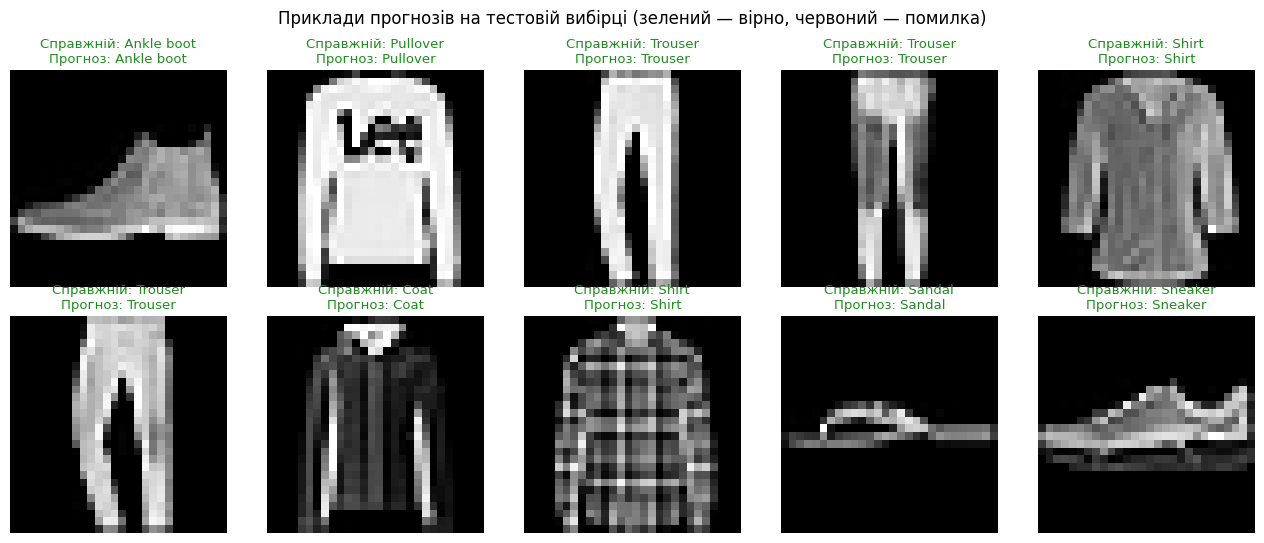

In [ ]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))

for i, ax in enumerate(axes.flat):
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred_classes[i]]
    is_correct = y_test[i] == y_pred_classes[i]
    color = "forestgreen" if is_correct else "firebrick"

    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"Справжній: {true_label}\nПрогноз: {pred_label}", color=color, fontsize=9.5)
    ax.axis("off")

plt.suptitle("Приклади прогнозів на тестовій вибірці (зелений — вірно, червоний — помилка)", fontsize=12)
plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
У ході лабораторної роботи я працювала з моделлю, яка розпізнає одяг і взуття з набору Fashion MNIST. На тестовій вибірці моя модель показала точність 0.8935 (89.35%) та тестові втрати 0.3129. Вимогу щодо мінімальної точності виконано, адже за умовою завдання поріг мав бути не нижче 0.87.

Також я переконалася, наскільки важливий етап нормалізації: якщо пропустити комірку з нормалізацією, модель отримує сирі значення пікселів від 0 до 255, через що їй набагато важче й довше вчитися, а точність падає нижче потрібного порогу. Нормалізація до діапазону [0; 1] (де значення лежать між нулем та одиницею) робить навчання стабільнішим і допомагає досягти вищого результату.

Загалом моя модель правильно класифікувала приблизно 8 935 із 10 000 тестових зображень одягу та взуття.

Найскладніші класи, які виявилися для моєї моделі:

Shirt (F1-score = 0.711, precision = 0.748, recall = 0.677)

Coat (F1-score = 0.811, precision = 0.806, recall = 0.815)

Pullover (F1-score = 0.818, precision = 0.796, recall = 0.841)

T-shirt/top (F1-score = 0.844, precision = 0.842, recall = 0.847)

Такі помилки виникають через те, що це плечовий одяг із подібною формою на невеликих картинках 28 × 28 пікселів (а перетворення через Flatten ще й спрощує просторові деталі), тому модель часто плутає ці речі між собою.

Найкраще моя модель розпізнає класи Trouser, Bag, Sandal, Ankle boot та Sneaker, оскільки вони мають чіткішу та більш відмінну одна від одної форму.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
%pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("Навчальна вибірка для пошуку:", x_train.shape, y_train.shape)
print("Валідаційна вибірка для пошуку:", x_val.shape, y_val.shape)
print("Тестова вибірка (лише для фінальної оцінки):", x_test.shape, y_test.shape)


Навчальна вибірка для пошуку: (51000, 28, 28) (51000,)
Валідаційна вибірка для пошуку: (9000, 28, 28) (9000,)
Тестова вибірка (лише для фінальної оцінки): (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:

def build_model(hp):
    model_hp = keras.Sequential()
    model_hp.add(keras.Input(shape=(28, 28)))
    model_hp.add(Flatten())

    # Пошук кількості прихованих шарів (від 1 до 3)
    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)

    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        dropout_rate = hp.Float(f"dropout_{i}", min_value=0.1, max_value=0.4, step=0.1)
        l2_reg = hp.Choice(f"l2_{i}", values=[1e-4, 1e-3])

        model_hp.add(Dense(
            units=units,
            activation="relu",
            kernel_regularizer=l2(l2_reg)
        ))
        model_hp.add(Dropout(rate=dropout_rate))

    model_hp.add(Dense(10, activation="softmax"))

    # Пошук швидкості навчання
    learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])

    model_hp.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    return model_hp

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="tuner_results",
    project_name="fashion_mnist_random_search",
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.4, 'step': 0.1, 'sampling': 'linear'}
l2_0 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

tuner_reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

tuner.search(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

# Отримуємо найкращі гіперпараметри
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nЗнайдені найкращі гіперпараметри:")
print(f"Кількість прихованих шарів: {best_hps.get('num_layers')}")
for i in range(best_hps.get("num_layers")):
    print(f"  Шар {i+1}: units={best_hps.get(f'units_{i}')}, "
          f"dropout={best_hps.get(f'dropout_{i}')}, l2={best_hps.get(f'l2_{i}')}")
print(f"Швидкість навчання (learning_rate): {best_hps.get('learning_rate')}")

# Будуємо та донавчаємо найкращу модель на train/val для збереження історії навчання
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

best_history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
    ],
    verbose=1
)

epochs_task2 = len(best_history.history["loss"])

Trial 3 Complete [00h 03m 59s]
val_accuracy: 0.8874444365501404

Best val_accuracy So Far: 0.8874444365501404
Total elapsed time: 00h 07m 31s

Знайдені найкращі гіперпараметри:
Кількість прихованих шарів: 3
  Шар 1: units=416, dropout=0.30000000000000004, l2=0.0001
  Шар 2: units=416, dropout=0.30000000000000004, l2=0.001
  Шар 3: units=32, dropout=0.1, l2=0.0001
Швидкість навчання (learning_rate): 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 416)            │       326,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 416)            │       173,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        13,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513,706 (1.96 MB)

 Trainable params: 513,706 (1.96 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7796 - loss: 0.8415 - val_accuracy: 0.8503 - val_loss: 0.5536 - learning_rate: 0.0010
Epoch 2/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8381 - loss: 0.5750 - val_accuracy: 0.8669 - val_loss: 0.4767 - learning_rate: 0.0010
Epoch 3/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8482 - loss: 0.5196 - val_accuracy: 0.8749 - val_loss: 0.4482 - learning_rate: 0.0010
Epoch 4/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8547 - loss: 0.5035 - val_accuracy: 0.8790 - val_loss: 0.4316 - learning_rate: 0.0010
Epoch 5/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8602 - loss: 0.4842 - val_accuracy: 0.8774 - val_loss: 0.4308 - learning_rate: 0.0010
Epoch 6/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8621 - loss: 0.4773 - val_accuracy: 0.8804 - val_loss: 0.4265 - learning_rate: 0.0010
Epoch 7/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.8658 - l

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Тестові втрати найкращої моделі (Loss): 0.4087
Тестова точність найкращої моделі (Accuracy): 0.8816 (88.16%)


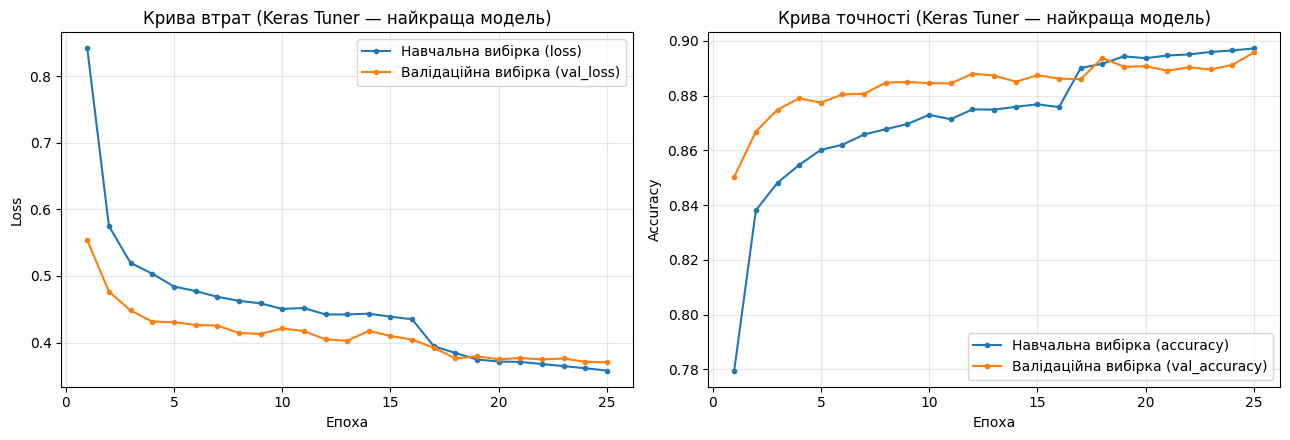

In [ ]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_2, test_acc_2 = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Тестові втрати найкращої моделі (Loss): {test_loss_2:.4f}")
print(f"Тестова точність найкращої моделі (Accuracy): {test_acc_2:.4f} ({test_acc_2:.2%})")

epochs_range_2 = np.arange(1, len(best_history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range_2, best_history.history["loss"], label="Навчальна вибірка (loss)", marker="o", ms=3)
axes[0].plot(epochs_range_2, best_history.history["val_loss"], label="Валідаційна вибірка (val_loss)", marker="o", ms=3)
axes[0].set_title("Крива втрат (Keras Tuner — найкраща модель)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range_2, best_history.history["accuracy"], label="Навчальна вибірка (accuracy)", marker="o", ms=3)
axes[1].plot(epochs_range_2, best_history.history["val_accuracy"], label="Валідаційна вибірка (val_accuracy)", marker="o", ms=3)
axes[1].set_title("Крива точності (Keras Tuner — найкраща модель)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 (dense_256 та dense_128) | 3 (dense_4, dense_5, dense_6) |
| Кількість нейронів | 256, 128 | 416, 416, 32 |
| Швидкість навчання |  0.001 |  0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8935| 0.8816 |
| Втрати на тестовій вибірці (loss) | 0.3129 | 0.4087 |
| Кількість епох навчання | 30 | 25  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
Так, досягли. Модель показала точність 0.8935 і це вище за мінімальний поріг 0.87.

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
Ні. Перша модель дала результати 0.8935,а друга модель (Keras Tuner) дала результати трохи низхчі 0.8816.

3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
На кроці 5 у завданні 2 Keras Tuner визначив такі найкращі гіперпараметри:

* кількість прихованих шарів: 3;

* 1-й шар: 416 нейронів, dropout = 0.3, L2 = 0.0001;

* 2-й шар: 416 нейронів, dropout = 0.3, L2 = 0.001;

* 3-й шар: 32 нейрони, dropout = 0.1, L2 = 0.0001;

* швидкість навчання (learning_rate): 0.001.

Результати можуть відрізнятися між запусками, оскільки метод RandomSearch випадково обирає комбінації параметрів із заданого діапазону, а під час навчання існують елементи випадковості (ініціалізація ваг, перемішування батчів, робота Dropout). Хоча на початку коду задано keras.utils.set_random_seed(42), під час перебору в Keras Tuner стан генератора випадкових чисел змінюється від спроби до спроби, та й при повторному запуску першої моделі результат може дещо змінюватися.


4. Які класи Fashion MNIST класифікувати найскладніше?
Найскладніше класифікувати верхній (плечовий) одяг — зокрема Shirt, Coat, Pullover та T-shirt/top, оскільки на невеликих зображеннях 28 × 28 пікселів вони мають подібну форму та силует і легко плутаються між собою.

**Власні висновки:**  
Обидві моделі впоралися з задачею, проте перша модель показала вищу точність на тесті (0.8935 проти 0.8816 у Keras Tuner) при менших втратах (0.3129 проти 0.4087). При повторних запусках під час випадкового пошуку в Keras Tuner і при перезапуску навчання першої моделі результати можуть відрізнятися через елементи випадковості в навчанні й підборі.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.